# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

In [2]:
import pandas as pd
rankdata = pd.read_csv('./data/rankdata.csv')
rankdata.head()

,cpu_time,feature_index,feature_rank,ranking_method,adapter,directory,path,replica_no,replicas,description,name,p,n,p_informative
0,3.855204,0,4.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
1,3.855204,1,11.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
2,3.855204,2,5.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
3,3.855204,3,3.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"
4,3.855204,4,11.0,RFE w/XGBoost,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,"Continuous Features [p=20,n=1600,h=0.4,edm=Easy]",Continuous Features,20,1600,"18,19"


## Ranking results
Measured cpu runtime on the ranking process.

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

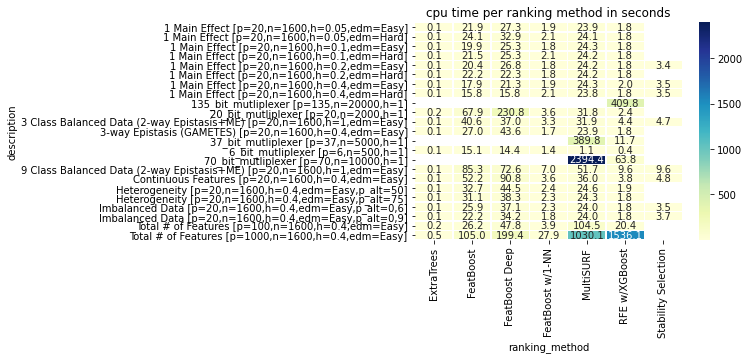

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(rankdata,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
g = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True)
plt.title('cpu time per ranking method in seconds')

Recall per algorithm iteration.

In [8]:
import numpy as np
from tqdm import tqdm

statdata = pd.DataFrame() # data, statistically post-processed

group_keys = ['description', 'ranking_method', 'replica_no']
for keys, rankset in tqdm(rankdata.groupby(group_keys)):
    description, ranking_method, replica_no = keys
    p_informatives = np.unique(rankset['p_informative'].values) # takes long for NaN's..
    if pd.isna(p_informatives).any(): # no `p_informative` set
        continue

    p_informative = [int(x) for x in p_informatives[0].split(',')]
    for feature_rank, ranks in rankset.groupby('feature_rank'):
        subset_rows = rankset[rankset['feature_rank'] <= feature_rank]
        subset = subset_rows['feature_index'].values

        n_positives = len(subset)
        n_true_positives = np.sum(np.isin(subset, p_informative))
        n_false_positives = n_positives - n_true_positives
        n_false_negatives = len(p_informative) - n_true_positives
        recall = n_true_positives / len(p_informative)
        precision = n_true_positives / n_positives

        stat = {
            'n_positives': n_positives,
            'n_true_positives': n_true_positives,
            'n_false_positives': n_false_positives,
            'n_false_negatives': n_false_negatives,
            'recall': recall,
            'precision': precision
        }
        statdata = statdata.append(ranks.assign(**stat))
statdata.to_csv('./data/statdata.csv', index=False)
statdata.shape

100%|██████████| 3135/3135 [35:59<00:00,  1.45it/s]


(95899, 20)